In [39]:
import pandas as pd
import matplotlib.pyplot as plt

READ THE CSV FILE

In [40]:
df=pd.read_csv('Spotify.csv')
print("csv file read successfully")

csv file read successfully


UNDERSTANDING THE DATASET

In [41]:
print("Data types:\n",df.dtypes)
df.head()

Data types:
 ids                      str
names                    str
popularity             int64
followers              int64
genres                   str
first_release          int64
last_release           int64
num_releases           int64
num_tracks             int64
monthly_listeners    float64
dtype: object


,ids,names,popularity,followers,genres,first_release,last_release,num_releases,num_tracks,monthly_listeners
0,68JRsR0O5ynf8xhu2jk2no,eqd,6,1974,NaN,2007,2023,10,2,1444.0
1,5VvZ6Br2O5ffnhkZt2HE8Q,チキンガーリックステーキ,3,140,NaN,2004,2010,12,2,231.0
2,2P3aLwJ41aRYkyFFw2FRM7,sam concepcion,45,168497,opm,2007,2023,20,1,583900.0
3,3ZzXi1Y1BvnvKJSVvzU2iP,vibemares,0,151,NaN,1996,1997,2,5,101.0
4,2ZC9B5qSrV48WOrOujZkNC,lantinor,0,1,NaN,2019,2019,1,12,0.0


In [42]:
print("Statistical summary:\n",df.describe())

Statistical summary:
          popularity     followers  first_release  last_release  num_releases  \
count  37000.000000  3.700000e+04   37000.000000  37000.000000  37000.000000   
mean       9.537486  3.966586e+04    1678.249162   1685.222027      6.124216   
std       14.112742  7.126790e+05     745.692094    748.741395      6.688222   
min        0.000000  0.000000e+00      -1.000000     -1.000000      0.000000   
25%        0.000000  2.900000e+01    1994.000000   2008.000000      1.000000   
50%        2.000000  2.020000e+02    2010.000000   2019.000000      3.000000   
75%       15.000000  1.726000e+03    2017.000000   2023.000000      9.000000   
max       92.000000  8.726594e+07    2024.000000   2024.000000     20.000000   

         num_tracks  monthly_listeners  
count  37000.000000       3.698800e+04  
mean       5.058514       1.096624e+05  
std       11.699609       1.246455e+06  
min        0.000000       0.000000e+00  
25%        1.000000       2.000000e+01  
50%        

In [43]:
print("Null values:\n",df.isnull().sum())

Null values:
 ids                      0
names                    0
popularity               0
followers                0
genres               24563
first_release            0
last_release             0
num_releases             0
num_tracks               0
monthly_listeners       12
dtype: int64


DATA TRANSFORMATION

In [44]:
print("deleting columns...")
df.drop(['genres','ids'],axis=1,inplace=True)
print("columns deleted.")


deleting columns...
columns deleted.


In [45]:
df['monthly_listeners']=df['monthly_listeners'].astype(float)
df['career_duration']=df['last_release']-df['first_release']

In [46]:
df.head()

,names,popularity,followers,first_release,last_release,num_releases,num_tracks,monthly_listeners,career_duration
0,eqd,6,1974,2007,2023,10,2,1444.0,16
1,チキンガーリックステーキ,3,140,2004,2010,12,2,231.0,6
2,sam concepcion,45,168497,2007,2023,20,1,583900.0,16
3,vibemares,0,151,1996,1997,2,5,101.0,1
4,lantinor,0,1,2019,2019,1,12,0.0,0


HANDLING NULL VALUES

In [47]:
print("Null values:\n",df.isnull().sum())

Null values:
 names                 0
popularity            0
followers             0
first_release         0
last_release          0
num_releases          0
num_tracks            0
monthly_listeners    12
career_duration       0
dtype: int64


In [48]:
df['monthly_listeners']=df['monthly_listeners'].fillna(df['monthly_listeners'].mean())
print("null values handled")
print("Null values:\n",df.isnull().sum())

null values handled
Null values:
 names                0
popularity           0
followers            0
first_release        0
last_release         0
num_releases         0
num_tracks           0
monthly_listeners    0
career_duration      0
dtype: int64


INSIGHTS

In [49]:
df.sort_values('monthly_listeners', ascending=False).head(10)


,names,popularity,followers,first_release,last_release,num_releases,num_tracks,monthly_listeners,career_duration
31222,drake,92,87265940,2009,2024,20,1,81358580.0,15
8802,miley cyrus,85,23371979,2007,2024,20,1,67841678.0,17
5548,olivia rodrigo,88,34059740,2016,2023,19,4,58313600.0,7
31893,katy perry,81,32842230,2008,2023,20,6,55922564.0,15
35215,onerepublic,80,16872206,2007,2024,20,1,55547707.0,17
33495,tate mcrae,81,5257127,2021,2024,20,1,54859791.0,3
29619,queen,81,49487244,1986,2022,20,16,51787211.0,36
17555,maluma,85,33513527,2012,2024,20,1,43105132.0,12
15554,bebe rexha,80,8928248,2018,2024,20,2,41458175.0,6
4296,lil wayne,85,14219491,2008,2023,20,16,38423559.0,15


In [50]:
first_release_group = df.groupby('first_release')[['popularity', 'monthly_listeners']].mean()
print(first_release_group)

               popularity  monthly_listeners
first_release                               
-1               2.378303        4337.799508
 1877            3.000000          47.000000
 1883            6.000000          92.000000
 1888            2.000000         467.000000
 1899           32.333333      113575.666667
...                   ...                ...
 2020           10.784177      105334.236184
 2021           11.059928      166142.302527
 2022           10.627264      116983.485224
 2023            7.964324      101934.465946
 2024            8.700000       76322.995455

[105 rows x 2 columns]


DATA VISUALIZATION

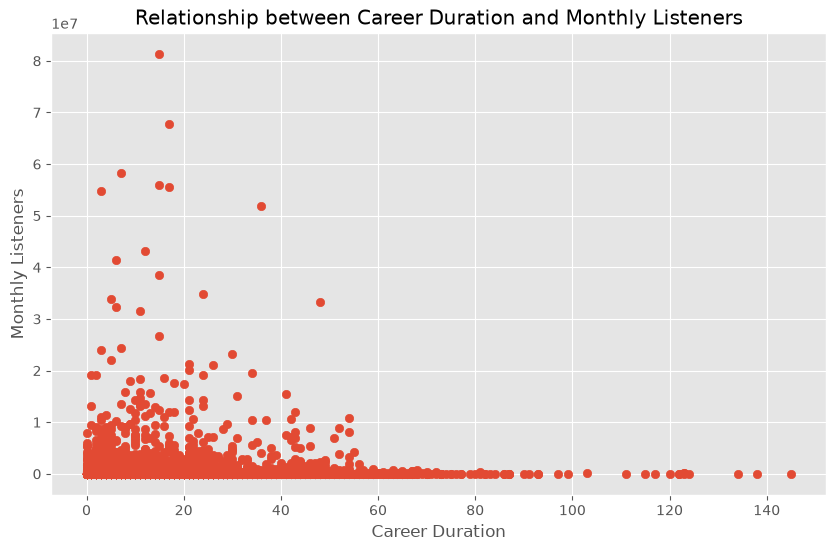

In [51]:
plt.figure(figsize=(10,6))
plt.scatter(df['career_duration'],df['monthly_listeners'])
plt.xlabel('Career Duration')
plt.ylabel('Monthly Listeners')
plt.title('Relationship between Career Duration and Monthly Listeners')
plt.show()

Text(0.5, 1.0, 'POPULARITY VS MONTHLY LISTENERS')

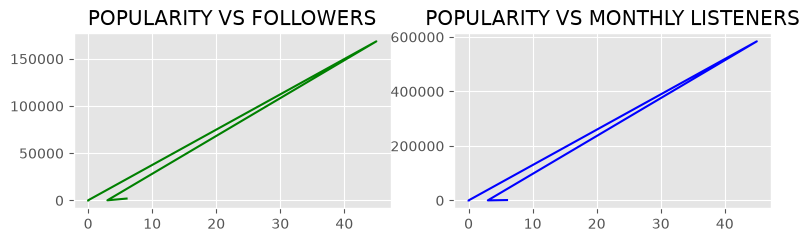

In [52]:
x=df['popularity'].head(5)
y1=df['followers'].head(5)
y2=df['monthly_listeners'].head(5)
plt.figure(figsize=(9,5))

plt.subplot(2,2,1)
plt.plot(x,y1,color='green')
plt.title("POPULARITY VS FOLLOWERS")

plt.subplot(2,2,2)
plt.plot(x,y2,color='blue')
plt.title("POPULARITY VS MONTHLY LISTENERS")


